Exploration & Feature Engineering

Practice project on the closed 2020 NFL Big Data Bowl (Kaggle). This notebook covers data standardization, hand-built feature engineering, and validation of several defender-geometry features (closing speed, interception-margin modeling, engaged-vs-free defender tiers). Best result: +2.4% CRPS skill over a no-features baseline.

A follow-up notebook (02_zoo_lite_network) implements a small version of the competition's 1st-place solution and gets +12.85%. See the project README for the full write-up.

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/nfl-big-data-bowl-2020/train.csv
/kaggle/input/competitions/nfl-big-data-bowl-2020/kaggle/competitions/nflrush/test.csv.encrypted
/kaggle/input/competitions/nfl-big-data-bowl-2020/kaggle/competitions/nflrush/sample_submission.csv.encrypted
/kaggle/input/competitions/nfl-big-data-bowl-2020/kaggle/competitions/nflrush/__init__.py
/kaggle/input/competitions/nfl-big-data-bowl-2020/kaggle/competitions/nflrush/competition.cpython-36m-x86_64-linux-gnu.so


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

df = pd.read_csv('/kaggle/input/competitions/nfl-big-data-bowl-2020/train.csv')
print(df.shape)

/tmp/ipykernel_16/3065563634.py:8: DtypeWarning: Columns (47) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('/kaggle/input/competitions/nfl-big-data-bowl-2020/train.csv')


(682154, 49)


In [3]:
df['ToLeft'] = df['PlayDirection'] == 'left'
df['X_std'] = df['X']
df.loc[df['ToLeft'], 'X_std'] = 120 - df.loc[df['ToLeft'], 'X']
df['Y_std'] = df['Y']
df.loc[df['ToLeft'], 'Y_std'] = (160/3) - df.loc[df['ToLeft'], 'Y']
df['Dir_std'] = df['Dir']
df.loc[df['ToLeft'], 'Dir_std'] = (df.loc[df['ToLeft'], 'Dir'] + 180) % 360

In [4]:
def compute_play_features(play_df):
    rusher_id = play_df['NflIdRusher'].iloc[0]
    rusher_row = play_df[play_df['NflId'] == rusher_id].iloc[0]
    rusher_team = rusher_row['Team']

    defenders = play_df[play_df['Team'] != rusher_team]
    dists = np.sqrt((defenders['X'] - rusher_row['X'])**2 + (defenders['Y'] - rusher_row['Y'])**2)

    linebackers = defenders[defenders['Position'].isin(['MLB', 'OLB', 'ILB', 'LB'])]
    lb_dists = np.sqrt((linebackers['X'] - rusher_row['X'])**2 + (linebackers['Y'] - rusher_row['Y'])**2)

    safeties = defenders[defenders['Position'].isin(['FS', 'SS', 'S', 'SAF'])]
    safety_dists = np.sqrt((safeties['X'] - rusher_row['X'])**2 + (safeties['Y'] - rusher_row['Y'])**2)
    has_safety = len(safeties) > 0

    field_pos = play_df['FieldPosition'].iloc[0]
    possession = play_df['PossessionTeam'].iloc[0]
    yard_line = play_df['YardLine'].iloc[0]
    yards_to_goal = 100 - yard_line if field_pos == possession else yard_line

    return pd.Series({
        'RusherSpeed': rusher_row['S'],
        'RusherAccel': rusher_row['A'],
        'MinDefenderDist': dists.min(),
        'AvgLBDist': lb_dists.mean(),
        'AvgSafetyDist': safety_dists.mean() if has_safety else 0,
        'YardsToGoal': yards_to_goal,
        'Yards': play_df['Yards'].iloc[0]
    })

features_full = df.groupby('PlayId').apply(compute_play_features, include_groups=False).reset_index()
print(features_full.shape)

(31007, 8)


In [5]:
check = df.groupby('PlayId').apply(
    lambda p: p.loc[p['NflId'] == p['NflIdRusher'].iloc[0], 'X_std'].iloc[0],
    include_groups=False
).reset_index(name='RusherX_std')

check = check.merge(features_full[['PlayId', 'YardsToGoal']], on='PlayId')
check['Expected'] = 110 - check['YardsToGoal']
check['Diff'] = (check['RusherX_std'] - check['Expected']).abs()
check['Diff'].describe()

count    31007.000000
mean         4.939156
std          0.931381
min          0.020000
25%          4.360000
50%          4.890000
75%          5.450000
max         12.770000
Name: Diff, dtype: float64

In [6]:
final_cols = ['RusherSpeed', 'RusherAccel', 'MinDefenderDist', 'AvgLBDist', 'AvgSafetyDist', 'YardsToGoal']
X = features_full[final_cols]
y = features_full['Yards']

model = RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42)
scores = cross_val_score(model, X, y, cv=5, scoring='neg_mean_absolute_error')
print(f"MAE across 5 folds: {-scores.mean():.3f} (+/- {scores.std():.3f})")

MAE across 5 folds: 3.712 (+/- 0.248)


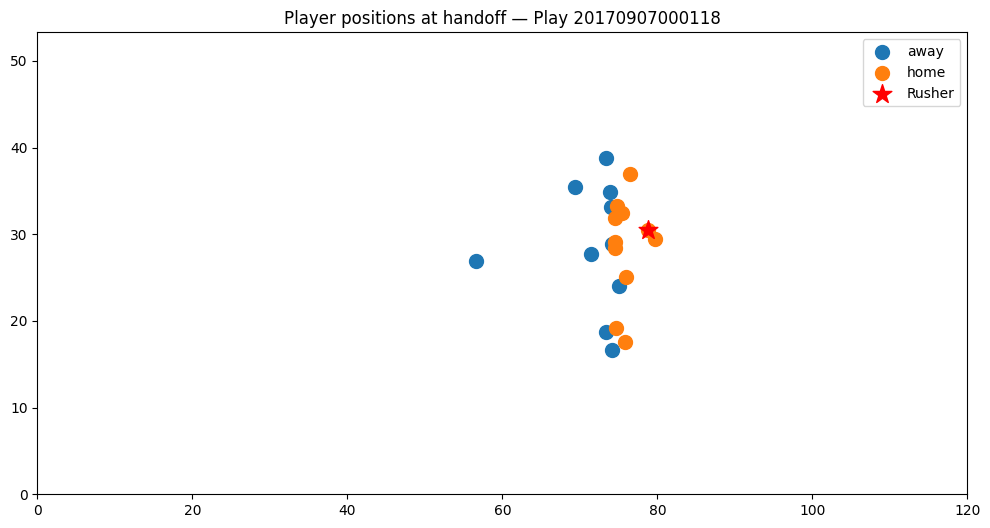

In [7]:
play_id = df['PlayId'].iloc[0]
one_play = df[df['PlayId'] == play_id]

rusher_id = one_play['NflIdRusher'].iloc[0]
rusher = one_play[one_play['NflId'] == rusher_id]

fig, ax = plt.subplots(figsize=(12, 6))
for team, group in one_play.groupby('Team'):
    ax.scatter(group['X'], group['Y'], label=team, s=100)

ax.scatter(rusher['X'], rusher['Y'], color='red', s=200, marker='*', label='Rusher', zorder=5)

ax.set_xlim(0, 120)
ax.set_ylim(0, 53.3)
ax.legend()
ax.set_title(f'Player positions at handoff — Play {play_id}')
plt.show()

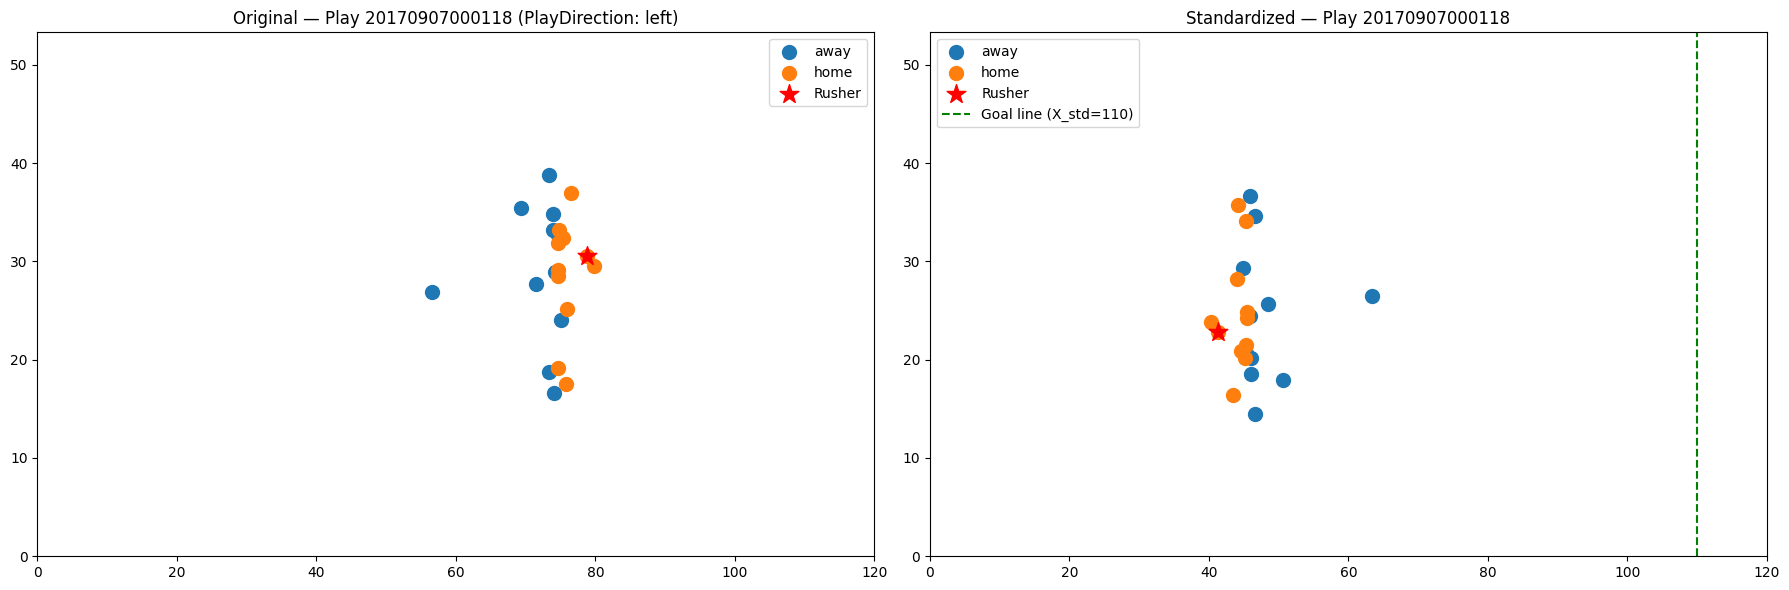

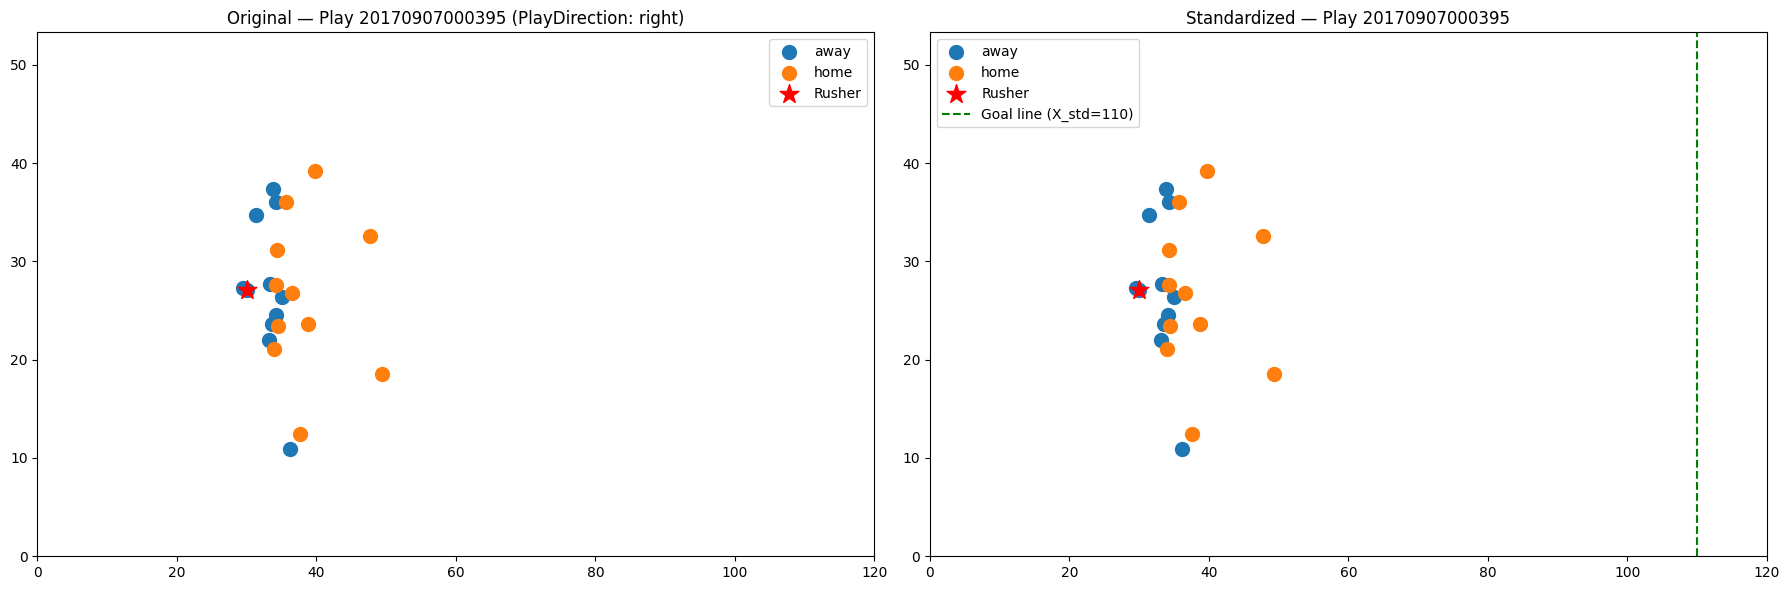

In [8]:
def plot_play_comparison(play_id):
    one_play = df[df['PlayId'] == play_id]
    rusher_id = one_play['NflIdRusher'].iloc[0]
    rusher = one_play[one_play['NflId'] == rusher_id]
    direction = one_play['PlayDirection'].iloc[0]

    fig, axes = plt.subplots(1, 2, figsize=(18, 6))

    # Original coordinates
    ax = axes[0]
    for team, group in one_play.groupby('Team'):
        ax.scatter(group['X'], group['Y'], label=team, s=100)
    ax.scatter(rusher['X'], rusher['Y'], color='red', s=200, marker='*', label='Rusher', zorder=5)
    ax.set_xlim(0, 120)
    ax.set_ylim(0, 53.3)
    ax.legend()
    ax.set_title(f'Original — Play {play_id} (PlayDirection: {direction})')

    # Standardized coordinates
    ax = axes[1]
    for team, group in one_play.groupby('Team'):
        ax.scatter(group['X_std'], group['Y_std'], label=team, s=100)
    ax.scatter(rusher['X_std'], rusher['Y_std'], color='red', s=200, marker='*', label='Rusher', zorder=5)
    ax.axvline(x=110, color='green', linestyle='--', label='Goal line (X_std=110)')
    ax.set_xlim(0, 120)
    ax.set_ylim(0, 53.3)
    ax.legend()
    ax.set_title(f'Standardized — Play {play_id}')

    plt.tight_layout()
    plt.show()

# Grab one 'left' play and one 'right' play to compare directly
left_play = df[df['PlayDirection'] == 'left']['PlayId'].iloc[0]
right_play = df[df['PlayDirection'] == 'right']['PlayId'].iloc[0]

plot_play_comparison(left_play)
plot_play_comparison(right_play)

In [9]:
# Check 1: is the gap consistent in sign for both ToLeft groups?
check_signed = df.groupby('PlayId').apply(
    lambda p: p.loc[p['NflId'] == p['NflIdRusher'].iloc[0], 'X_std'].iloc[0],
    include_groups=False
).reset_index(name='RusherX_std')
check_signed = check_signed.merge(features_full[['PlayId', 'YardsToGoal']], on='PlayId')
check_signed = check_signed.merge(df.drop_duplicates('PlayId')[['PlayId', 'ToLeft', 'OffenseFormation']], on='PlayId')
check_signed['Expected'] = 110 - check_signed['YardsToGoal']
check_signed['SignedDiff'] = check_signed['RusherX_std'] - check_signed['Expected']
check_signed.groupby('ToLeft')['SignedDiff'].describe()

# Check 2: does gap size track formation depth?
check_signed.groupby('OffenseFormation')['SignedDiff'].mean().sort_values()

OffenseFormation
PISTOL       -5.369785
I_FORM       -5.181754
SINGLEBACK   -5.158604
WILDCAT      -4.741039
EMPTY        -4.716452
ACE          -4.680000
SHOTGUN      -4.463188
JUMBO        -4.299424
Name: SignedDiff, dtype: float64

In [10]:
check_signed.groupby('ToLeft')['SignedDiff'].describe()

,count,mean,std,min,25%,50%,75%,max
ToLeft,,,,,,,,
False,15352.0,-4.976291,0.934030,-10.46,-5.49,-4.93,-4.40,0.18
True,15655.0,-4.902607,0.928066,-12.77,-5.41,-4.85,-4.33,0.84


In [11]:
rusher_motion = df[df['NflId'] == df['NflIdRusher']].copy()

angle_rad = np.radians(90 - rusher_motion['Dir_std'])
rusher_motion['vx_std'] = rusher_motion['S'] * np.cos(angle_rad)
rusher_motion['vy_std'] = rusher_motion['S'] * np.sin(angle_rad)

(rusher_motion['vx_std'] > 0).mean()

np.float64(0.9661689295965428)

In [12]:
# 1. Pull each play's rusher position and team, attach to every row of that play
rush = df.loc[df['NflId'] == df['NflIdRusher'], ['PlayId', 'X_std', 'Y_std', 'Team']]
rush = rush.rename(columns={'X_std': 'rX', 'Y_std': 'rY', 'Team': 'rTeam'})
d = df.merge(rush, on='PlayId')

# 2. Keep defenders only
d = d[d['Team'] != d['rTeam']].copy()

# 3. Vector from defender to rusher, and its length
d['dx'] = d['rX'] - d['X_std']
d['dy'] = d['rY'] - d['Y_std']
d['dist'] = np.hypot(d['dx'], d['dy'])

# 4. Defender velocity components (same conversion you just validated)
ang = np.radians(90 - d['Dir_std'])
d['vx'] = d['S'] * np.cos(ang)
d['vy'] = d['S'] * np.sin(ang)

# 5. Closing speed = velocity projected onto the defender->rusher direction
d['closing'] = (d['vx'] * d['dx'] + d['vy'] * d['dy']) / d['dist']

# 6. Keep just the nearest defender per play
nearest = d.loc[d.groupby('PlayId')['dist'].idxmin(), ['PlayId', 'dist', 'closing']]
nearest['closing'].describe()

count    31003.000000
mean         1.033132
std          1.240813
min         -3.503905
25%          0.144977
50%          0.821740
75%          1.758617
max          7.117948
Name: closing, dtype: float64

In [13]:
# Sanity check first: our nearest-defender distance should match MinDefenderDist from Cell 3
chk = nearest.merge(features_full[['PlayId', 'MinDefenderDist']], on='PlayId')
print((chk['dist'] - chk['MinDefenderDist']).abs().max())   # expect ~0

# Merge closing speed in; fill the 4 NaN plays with the median
features_v2 = features_full.merge(nearest[['PlayId', 'closing']], on='PlayId', how='left')
features_v2['closing'] = features_v2['closing'].fillna(features_v2['closing'].median())
features_v2 = features_v2.rename(columns={'closing': 'NearestClosingSpeed'})

# Same model, same 5-fold CV, one added feature
cols_v2 = final_cols + ['NearestClosingSpeed']
scores = cross_val_score(
    RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42),
    features_v2[cols_v2], features_v2['Yards'],
    cv=5, scoring='neg_mean_absolute_error'
)
print(f"MAE across 5 folds: {-scores.mean():.3f} (+/- {scores.std():.3f})")

1.509903313490213e-14
MAE across 5 folds: 3.710 (+/- 0.245)


In [14]:
print(df['Position'].unique())

['SS' 'DE' 'ILB' 'FS' 'CB' 'DT' 'WR' 'TE' 'T' 'QB' 'RB' 'G' 'C' 'OLB' 'NT'
 'FB' 'MLB' 'LB' 'OT' 'S' 'OG' 'HB' 'DB' 'DL' 'SAF']


In [15]:
OL_POS = ['T', 'G', 'C', 'OT', 'OG']

# --- One play, eyeballed ---
p = df[df['PlayId'] == df['PlayId'].iloc[0]]
rusher_team = p.loc[p['NflId'] == p['NflIdRusher'].iloc[0], 'Team'].iloc[0]
ol = p[(p['Team'] == rusher_team) & (p['Position'].isin(OL_POS))].sort_values('Y_std')

print(ol[['Position', 'X_std', 'Y_std']])
print("Gap midpoints (Y):", ((ol['Y_std'].values[:-1] + ol['Y_std'].values[1:]) / 2).round(2))

# --- Whole dataset: how many OL per play? ---
d2 = df.merge(rush[['PlayId', 'rTeam']], on='PlayId')
ol_counts = d2[(d2['Team'] == d2['rTeam']) & (d2['Position'].isin(OL_POS))].groupby('PlayId').size()
print(ol_counts.value_counts().sort_index())

   Position  X_std      Y_std
13        T  44.57  20.923333
19        G  45.40  21.453333
20        C  45.42  24.213333
21        G  45.42  24.863333
14        T  44.10  28.213333
Gap midpoints (Y): [21.19 22.83 24.54 26.54]
4       75
5    28780
6     2089
7       63
Name: count, dtype: int64


In [16]:
# Uses p, rusher_team, and ol from the previous cell (re-run it first if the kernel reset)
defenders = p[p['Team'] != rusher_team]
ol_sorted = ol.reset_index(drop=True)

rows = []
for i in range(len(ol_sorted) - 1):
    a, b = ol_sorted.iloc[i], ol_sorted.iloc[i + 1]
    gx = (a['X_std'] + b['X_std']) / 2
    gy = (a['Y_std'] + b['Y_std']) / 2
    dist_to_def = np.hypot(defenders['X_std'] - gx, defenders['Y_std'] - gy)
    rows.append({
        'gap': f"{a['Position']}-{b['Position']}",
        'gy': gy,
        'width': b['Y_std'] - a['Y_std'],
        'nearest_def_dist': dist_to_def.min(),
        'nearest_def_pos': defenders.loc[dist_to_def.idxmin(), 'Position'],
    })

pd.DataFrame(rows).round(2)

,gap,gy,width,nearest_def_dist,nearest_def_pos
0,T-G,21.19,0.53,0.60,DE
1,G-C,22.83,2.76,1.66,DT
2,C-G,24.54,0.65,0.44,DT
3,G-T,26.54,3.35,2.37,DT


In [17]:
# Uses ol_sorted and defenders from the previous cell
rows = []
for _, dfn in defenders.iterrows():
    dists = np.hypot(ol_sorted['X_std'] - dfn['X_std'], ol_sorted['Y_std'] - dfn['Y_std'])
    rows.append({
        'pos': dfn['Position'],
        'X': dfn['X_std'],
        'Y': dfn['Y_std'],
        'dist_to_nearest_OL': dists.min(),
        'nearest_OL': ol_sorted.loc[dists.idxmin(), 'Position'],
    })

pd.DataFrame(rows).sort_values('dist_to_nearest_OL').round(2)

,pos,X,Y,dist_to_nearest_OL,nearest_OL
10,DT,45.85,24.43,0.48,C
1,DE,45.33,20.69,0.76,G
5,DE,44.94,29.33,1.40,T
2,DE,46.00,20.13,1.45,G
0,SS,46.09,18.49,2.87,T
3,ILB,48.54,25.63,3.21,G
4,FS,50.68,17.91,6.36,G
9,CB,46.65,14.50,6.75,T
7,CB,46.63,34.60,6.87,T
6,CB,45.89,36.69,8.67,T


In [18]:
OL_POS = ['T', 'G', 'C', 'OT', 'OG']

base = df.merge(rush[['PlayId', 'rTeam']], on='PlayId')
ol_all = (base[(base['Team'] == base['rTeam']) & (base['Position'].isin(OL_POS))]
          [['PlayId', 'X_std', 'Y_std']].rename(columns={'X_std': 'oX', 'Y_std': 'oY'}))
def_all = base[base['Team'] != base['rTeam']][['PlayId', 'NflId', 'Position', 'X_std', 'Y_std']]

pairs = def_all.merge(ol_all, on='PlayId')
pairs['dist'] = np.hypot(pairs['X_std'] - pairs['oX'], pairs['Y_std'] - pairs['oY'])
def_ol = pairs.groupby(['PlayId', 'NflId'])['dist'].min().reset_index(name='dist_to_nearest_OL')

# Shape of the distribution
bins = np.arange(0, 10.5, 0.5)
print(pd.cut(def_ol['dist_to_nearest_OL'], bins).value_counts().sort_index())

# Probe (not a decision): how many defenders per play fall under 2 yards?
print((def_ol['dist_to_nearest_OL'] < 2).groupby(def_ol['PlayId']).sum().value_counts().sort_index())

dist_to_nearest_OL
(0.0, 0.5]      7709
(0.5, 1.0]     75621
(1.0, 1.5]     30841
(1.5, 2.0]     18266
(2.0, 2.5]     17775
(2.5, 3.0]     17294
(3.0, 3.5]     15693
(3.5, 4.0]     13201
(4.0, 4.5]     10475
(4.5, 5.0]      8205
(5.0, 5.5]      6772
(5.5, 6.0]      5610
(6.0, 6.5]      4990
(6.5, 7.0]      4663
(7.0, 7.5]      4310
(7.5, 8.0]      4254
(8.0, 8.5]      4244
(8.5, 9.0]      4191
(9.0, 9.5]      4390
(9.5, 10.0]     4261
Name: count, dtype: int64
dist_to_nearest_OL
0         2
1        16
2       719
3      6534
4     12378
5      7312
6      3155
7       768
8       106
9        14
10        3
Name: count, dtype: int64


In [19]:
spd = df[['PlayId', 'NflId', 'S']]
chk = def_ol.merge(spd, on=['PlayId', 'NflId'])
chk['band'] = pd.cut(chk['dist_to_nearest_OL'], [0, 1, 1.5, 2, 2.5, 3, 4, 6, 10])

print(chk.groupby('band', observed=True)['S']
         .describe()[['count', 'mean', '25%', '50%', '75%']].round(2))

               count  mean   25%   50%   75%
band                                        
(0.0, 1.0]   83330.0  1.97  1.07  1.85  2.76
(1.0, 1.5]   30841.0  2.40  1.44  2.29  3.27
(1.5, 2.0]   18266.0  2.71  1.72  2.59  3.60
(2.0, 2.5]   17775.0  2.81  1.82  2.71  3.71
(2.5, 3.0]   17294.0  2.82  1.84  2.73  3.73
(3.0, 4.0]   28894.0  2.75  1.77  2.63  3.63
(4.0, 6.0]   31062.0  2.57  1.55  2.42  3.43
(6.0, 10.0]  35303.0  2.38  1.42  2.25  3.17


In [20]:
proj = rusher_motion[['PlayId', 'X_std', 'Y_std', 'vx_std', 'vy_std']].merge(
    features_full[['PlayId', 'YardsToGoal']], on='PlayId')

proj['LOS_X'] = 110 - proj['YardsToGoal']
proj['dist_to_LOS'] = proj['LOS_X'] - proj['X_std']          # ~4.9 on average
proj['t_to_LOS'] = proj['dist_to_LOS'] / proj['vx_std']       # seconds, if vx > 0
proj['cross_Y'] = proj['Y_std'] + proj['vy_std'] * proj['t_to_LOS']

ok = proj[proj['vx_std'] > 0.5]     # skip rushers barely moving downfield
print(len(ok), "of", len(proj), "plays have vx > 0.5")
print(ok[['t_to_LOS']].describe().round(2))
print((ok['cross_Y'] - ok['Y_std']).describe().round(2))    # lateral shift by the LOS

29201 of 31007 plays have vx > 0.5
       t_to_LOS
count  29201.00
mean       2.05
std        1.59
min       -1.30
25%        1.24
50%        1.57
75%        2.15
max       16.37
count    29201.00
mean         0.38
std         10.69
min        -97.60
25%         -3.43
50%         -0.11
75%          3.84
max        111.41
dtype: float64


In [21]:
p2 = rusher_motion[['PlayId', 'X_std', 'Y_std', 'S', 'A', 'vx_std', 'vy_std']].merge(
    features_full[['PlayId', 'YardsToGoal']], on='PlayId')

p2['dist'] = (110 - p2['YardsToGoal'] - p2['X_std']).clip(lower=0)   # already past LOS -> 0
moving = p2['vx_std'] > 0.5

ux = p2['vx_std'] / p2['S']
uy = p2['vy_std'] / p2['S']
s = p2['dist'] / ux.where(moving)          # path distance along his heading to reach the LOS

# constant acceleration along the path: 0.5*A*t^2 + S*t - s = 0
A = p2['A'].clip(lower=0.1)
p2['t_to_LOS'] = (-p2['S'] + np.sqrt(p2['S']**2 + 2 * A * s)) / A

# crossing point: keep on the field, and fall back to "straight ahead" when not moving downfield
p2['cross_Y'] = (p2['Y_std'] + uy * s).clip(0, 53.3)
p2.loc[~moving, 'cross_Y'] = p2.loc[~moving, 'Y_std']

print(p2.loc[moving, 't_to_LOS'].describe().round(2))
print((p2['cross_Y'] - p2['Y_std']).describe().round(2))
print("hit the sideline clip:", ((p2['cross_Y'] <= 0) | (p2['cross_Y'] >= 53.3)).sum())

count    29201.00
mean         1.34
std          0.69
min          0.00
25%          0.96
50%          1.15
75%          1.44
max          9.16
Name: t_to_LOS, dtype: float64
count    31007.00
mean         0.21
std          7.77
min        -31.75
25%         -3.13
50%          0.00
75%          3.54
max         30.55
dtype: float64
hit the sideline clip: 1274


In [22]:
LOS = features_full[['PlayId', 'YardsToGoal']].copy()
LOS['LOS_X'] = 110 - LOS['YardsToGoal']

free = def_all.merge(def_ol, on=['PlayId', 'NflId'])
free = free[free['dist_to_nearest_OL'] >= 2.0]
free = (free.merge(p2[['PlayId', 'cross_Y', 't_to_LOS']], on='PlayId')
            .merge(LOS[['PlayId', 'LOS_X']], on='PlayId')
            .dropna(subset=['t_to_LOS']))

free['dist_to_cross'] = np.hypot(free['X_std'] - free['LOS_X'], free['Y_std'] - free['cross_Y'])

DEF_SPEED = 6.0                      # yd/s, an assumption, so we'll test 5 and 7 too
free['def_time'] = free['dist_to_cross'] / DEF_SPEED
free['margin'] = free['def_time'] - free['t_to_LOS']     # negative = defender gets there first

best = free.groupby('PlayId')['margin'].min()
print(best.describe().round(2))
print("share of plays with a defender who arrives first:", (best < 0).mean().round(3))
print("free defenders per play:")
print(free.groupby('PlayId').size().describe().round(1))

count    29201.00
mean        -0.62
std          0.50
min         -6.11
25%         -0.86
50%         -0.58
75%         -0.33
max          1.88
Name: margin, dtype: float64
share of plays with a defender who arrives first: 0.929
free defenders per play:
count    29201.0
mean         6.7
std          1.1
min          1.0
25%          6.0
50%          7.0
75%          7.0
max         10.0
dtype: float64


In [23]:
def margin_feats(speed=6.0, cutoff=2.0):
    fr = def_all.merge(def_ol, on=['PlayId', 'NflId'])
    fr = fr[fr['dist_to_nearest_OL'] >= cutoff]
    fr = (fr.merge(p2[['PlayId', 'cross_Y', 't_to_LOS']], on='PlayId')
            .merge(LOS[['PlayId', 'LOS_X']], on='PlayId')
            .dropna(subset=['t_to_LOS']))
    fr['t_to_LOS'] = fr['t_to_LOS'].clip(upper=3)
    dist = np.hypot(fr['X_std'] - fr['LOS_X'], fr['Y_std'] - fr['cross_Y'])
    fr['margin'] = dist / speed - fr['t_to_LOS']
    g = fr.groupby('PlayId')['margin']
    return pd.DataFrame({
        'BestMargin': g.min(),
        'NumBeatHim': (fr['margin'] < 0).groupby(fr['PlayId']).sum(),
        'NumBeatBy05': (fr['margin'] < -0.5).groupby(fr['PlayId']).sum(),
    }).reset_index()

for spd in [5.0, 6.0, 7.0]:
    X = features_full.merge(margin_feats(speed=spd), on='PlayId', how='left')
    new = ['BestMargin', 'NumBeatHim', 'NumBeatBy05']
    for c in new:
        X[c] = X[c].fillna(X[c].median())      # the 1,806 non-downfield plays
    scores = cross_val_score(
        RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42),
        X[final_cols + new], X['Yards'],
        cv=5, scoring='neg_mean_absolute_error'
    )
    print(f"speed={spd}: MAE {-scores.mean():.3f} (+/- {scores.std():.3f})")

speed=5.0: MAE 3.712 (+/- 0.250)
speed=6.0: MAE 3.710 (+/- 0.250)
speed=7.0: MAE 3.710 (+/- 0.252)


In [24]:
from sklearn.model_selection import cross_val_predict
from scipy.stats import spearmanr

X = features_full.merge(margin_feats(speed=6.0), on='PlayId', how='left')
new = ['BestMargin', 'NumBeatHim', 'NumBeatBy05']
has = X['BestMargin'].notna()          # drop the 1,806 non-downfield plays for this check
X = X[has].reset_index(drop=True)

# Out-of-fold predictions from the baseline features only
oof = cross_val_predict(
    RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42),
    X[final_cols], X['Yards'], cv=5
)
resid = X['Yards'] - oof

for c in new:
    r_y, _ = spearmanr(X[c], X['Yards'])
    r_res, _ = spearmanr(X[c], resid)
    print(f"{c:12s}  vs Yards: {r_y:+.3f}   vs baseline residual: {r_res:+.3f}")

BestMargin    vs Yards: +0.135   vs baseline residual: +0.103
NumBeatHim    vs Yards: -0.099   vs baseline residual: -0.041
NumBeatBy05   vs Yards: -0.130   vs baseline residual: -0.083


In [25]:
from sklearn.model_selection import cross_validate

Xf = features_full.merge(margin_feats(speed=6.0), on='PlayId', how='left')
new = ['BestMargin', 'NumBeatHim', 'NumBeatBy05']
for c in new:
    Xf[c] = Xf[c].fillna(Xf[c].median())

rf = RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42)
metrics = {'rmse': 'neg_root_mean_squared_error', 'r2': 'r2', 'mae': 'neg_mean_absolute_error'}

for name, cols in [('baseline', final_cols), ('+ margin feats', final_cols + new)]:
    cv = cross_validate(rf, Xf[cols], Xf['Yards'], cv=5, scoring=metrics)
    print(f"{name:15s} RMSE {-cv['test_rmse'].mean():.3f}  "
          f"R2 {cv['test_r2'].mean():.4f}  MAE {-cv['test_mae'].mean():.3f}")

baseline        RMSE 6.303  R2 0.0434  MAE 3.712
+ margin feats  RMSE 6.302  R2 0.0435  MAE 3.710


In [26]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression

# A: can a simple linear model predict the baseline's residuals from the new features?
r2_resid = cross_val_score(LinearRegression(), X[new], resid, cv=5, scoring='r2')
print(f"Residual R2 from new features (linear): {r2_resid.mean():.4f}")

# B: same baseline-vs-new comparison with gradient boosting instead of a depth-5 forest
hgb = HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=200, random_state=42)
for name, cols in [('baseline', final_cols), ('+ margin feats', final_cols + new)]:
    cv = cross_validate(hgb, Xf[cols], Xf['Yards'], cv=5, scoring=metrics)
    print(f"{name:15s} RMSE {-cv['test_rmse'].mean():.3f}  R2 {cv['test_r2'].mean():.4f}  MAE {-cv['test_mae'].mean():.3f}")

Residual R2 from new features (linear): 0.0012
baseline        RMSE 6.295  R2 0.0458  MAE 3.691
+ margin feats  RMSE 6.289  R2 0.0477  MAE 3.685


In [27]:
cv_b = cross_validate(hgb, Xf[final_cols], Xf['Yards'], cv=5, scoring=metrics)
cv_n = cross_validate(hgb, Xf[final_cols + new], Xf['Yards'], cv=5, scoring=metrics)
print((cv_n['test_rmse'] - cv_b['test_rmse']).round(4))   # positive = new features better

[ 0.0134  0.0127 -0.0009  0.0101 -0.0039]


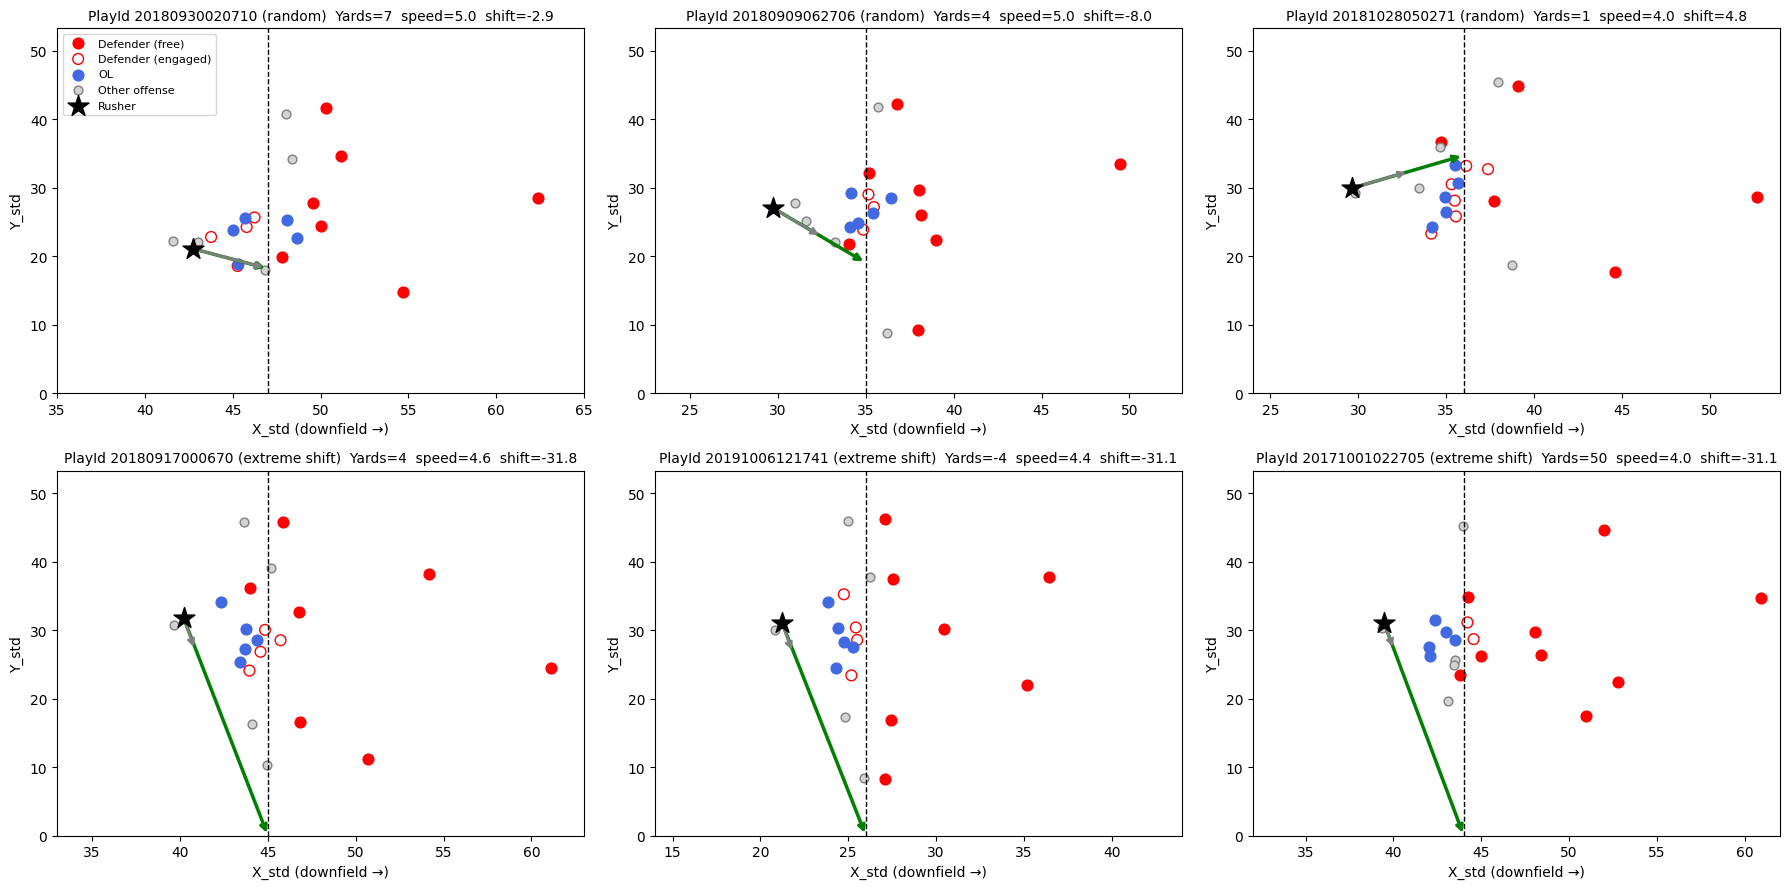

In [28]:
import matplotlib.pyplot as plt

OL_POS = ['T', 'G', 'C', 'OT', 'OG']

plot_df = p2.set_index('PlayId').join(features_full.set_index('PlayId')[['Yards']])
plot_df['LOS_X'] = 110 - plot_df['YardsToGoal']
plot_df['shift'] = plot_df['cross_Y'] - plot_df['Y_std']
moving_only = plot_df[plot_df['vx_std'] > 0.5]

rand_ids = list(moving_only.sample(3, random_state=1).index)
extreme_ids = list(moving_only['shift'].abs().nlargest(3).index)
ids = rand_ids + extreme_ids

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, pid in zip(axes.flat, ids):
    r = plot_df.loc[pid]
    play = base[base['PlayId'] == pid]
    off = play[play['Team'] == play['rTeam']]
    dfn = play[play['Team'] != play['rTeam']]
    ol = off[off['Position'].isin(OL_POS)]

    # defenders: filled if free (>= 2 yd from any OL), hollow if engaged
    d_free = def_ol.set_index(['PlayId', 'NflId'])['dist_to_nearest_OL']
    dist = np.array([d_free.get((pid, n), np.nan) for n in dfn['NflId']])
    free = dist >= 2.0
    ax.scatter(dfn['X_std'][free], dfn['Y_std'][free], c='red', s=60, label='Defender (free)')
    ax.scatter(dfn['X_std'][~free], dfn['Y_std'][~free], facecolors='none',
               edgecolors='red', s=60, label='Defender (engaged)')
    ax.scatter(ol['X_std'], ol['Y_std'], c='royalblue', s=60, label='OL')
    ax.scatter(off['X_std'][~off['Position'].isin(OL_POS)],
               off['Y_std'][~off['Position'].isin(OL_POS)],
               c='lightgray', edgecolors='gray', s=40, label='Other offense')

    ax.scatter([r['X_std']], [r['Y_std']], marker='*', c='black', s=250, label='Rusher', zorder=5)
    ax.axvline(r['LOS_X'], color='k', ls='--', lw=1)

    # projected path: rusher -> crossing point on the LOS
    ax.annotate('', xy=(r['LOS_X'], r['cross_Y']), xytext=(r['X_std'], r['Y_std']),
                arrowprops=dict(arrowstyle='->', color='green', lw=2.5), zorder=4)
    # velocity at handoff (x1 scale so it's visible)
    ax.annotate('', xy=(r['X_std'] + r['vx_std'], r['Y_std'] + r['vy_std']),
                xytext=(r['X_std'], r['Y_std']),
                arrowprops=dict(arrowstyle='->', color='gray', lw=2), zorder=4)

    tag = 'random' if pid in rand_ids else 'extreme shift'
    ax.set_title(f"PlayId {pid} ({tag})  Yards={r['Yards']:.0f}  "
                 f"speed={r['S']:.1f}  shift={r['shift']:.1f}", fontsize=10)
    ax.set_xlim(r['LOS_X'] - 12, r['LOS_X'] + 18)
    ax.set_ylim(0, 53.3)
    ax.set_xlabel('X_std (downfield →)')
    ax.set_ylabel('Y_std')

axes.flat[0].legend(loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()

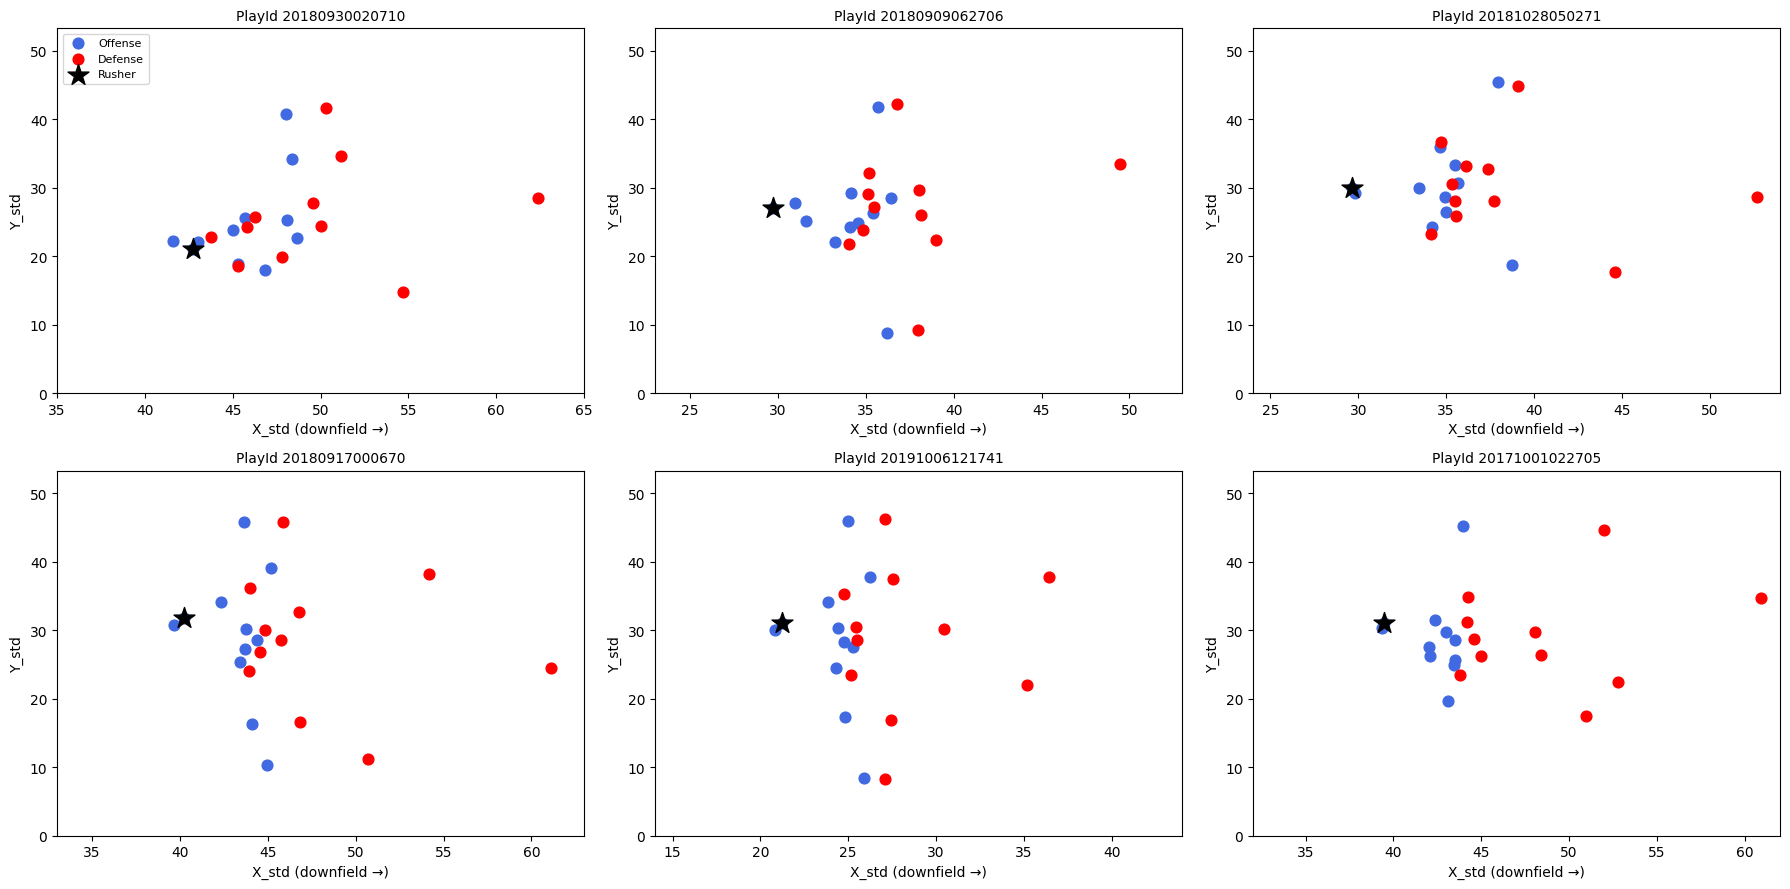

In [29]:
ids = [20180930020710, 20180909062706, 20181028050271,
       20180917000670, 20191006121741, 20171001022705]

los = features_full.set_index('PlayId')['YardsToGoal'].rsub(110)   # LOS_X, only used to frame the axes

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, pid in zip(axes.flat, ids):
    play = base[base['PlayId'] == pid]
    off = play[play['Team'] == play['rTeam']]
    dfn = play[play['Team'] != play['rTeam']]
    rush_row = off[off['NflId'] == off['NflIdRusher']]

    ax.scatter(off['X_std'], off['Y_std'], c='royalblue', s=60, label='Offense')
    ax.scatter(dfn['X_std'], dfn['Y_std'], c='red', s=60, label='Defense')
    ax.scatter(rush_row['X_std'], rush_row['Y_std'], marker='*', c='black', s=250,
               zorder=5, label='Rusher')

    ax.set_title(f"PlayId {pid}", fontsize=10)
    ax.set_xlim(los[pid] - 12, los[pid] + 18)
    ax.set_ylim(0, 53.3)
    ax.set_xlabel('X_std (downfield →)')
    ax.set_ylabel('Y_std')

axes.flat[0].legend(loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()

In [30]:
cal = features_full[['PlayId', 'Yards']].merge(
    margin_feats(speed=6.0)[['PlayId', 'BestMargin']], on='PlayId').dropna()
cal['quintile'] = pd.qcut(cal['BestMargin'], 5)

print(cal.groupby('quintile', observed=True)['Yards'].agg(
    plays='count', mean='mean', median='median',
    stuffed=lambda s: (s <= 0).mean()).round(2))
print("Overall share of plays with Yards <= 0:", round((cal['Yards'] <= 0).mean(), 3))

                               plays  mean  median  stuffed
quintile                                                   
(-2.9819999999999998, -0.917]   5841  3.39     2.0     0.29
(-0.917, -0.666]                5840  4.00     3.0     0.22
(-0.666, -0.471]                5840  4.24     3.0     0.18
(-0.471, -0.253]                5840  4.45     3.0     0.14
(-0.253, 1.881]                 5840  4.89     3.0     0.14
Overall share of plays with Yards <= 0: 0.194


In [31]:
# Current geometry only: no projected path, no heading assumption
fr = (def_all.merge(def_ol, on=['PlayId', 'NflId'])
             .merge(rush[['PlayId', 'rX', 'rY']], on='PlayId'))
fr['dist_to_rusher'] = np.hypot(fr['X_std'] - fr['rX'], fr['Y_std'] - fr['rY'])
free_now = fr[fr['dist_to_nearest_OL'] >= 2.0]      # same soft cutoff as before

geo = pd.DataFrame({
    'NearestFreeDist': free_now.groupby('PlayId')['dist_to_rusher'].min(),
    'NumFreeWithin4': (free_now['dist_to_rusher'] < 4).groupby(free_now['PlayId']).sum(),
}).reindex(features_full['PlayId']).reset_index()
geo['NearestFreeDist'] = geo['NearestFreeDist'].fillna(geo['NearestFreeDist'].max())
geo['NumFreeWithin4'] = geo['NumFreeWithin4'].fillna(0)

# 1. Calibration, same as before
cal2 = features_full[['PlayId', 'Yards']].merge(geo, on='PlayId')
cal2['quintile'] = pd.qcut(cal2['NearestFreeDist'], 5, duplicates='drop')
print(cal2.groupby('quintile', observed=True)['Yards'].agg(
    plays='count', mean='mean', median='median',
    stuffed=lambda s: (s <= 0).mean()).round(2))

# 2. Does it add anything on top of the baseline? Paired folds, gradient boosting
Xg = features_full.merge(geo, on='PlayId')
new_g = ['NearestFreeDist', 'NumFreeWithin4']
cv_b = cross_validate(hgb, Xg[final_cols], Xg['Yards'], cv=5, scoring=metrics)
cv_n = cross_validate(hgb, Xg[final_cols + new_g], Xg['Yards'], cv=5, scoring=metrics)
print("RMSE improvement per fold (positive = better):", (cv_b['test_rmse'] - cv_n['test_rmse']).round(4))
print(f"Mean R2: {cv_b['test_r2'].mean():.4f} -> {cv_n['test_r2'].mean():.4f}")

                 plays  mean  median  stuffed
quintile                                     
(0.268, 5.65]     6202  4.15     3.0     0.22
(5.65, 6.506]     6201  3.98     3.0     0.20
(6.506, 7.235]    6201  4.33     3.0     0.19
(7.235, 8.064]    6201  4.23     3.0     0.19
(8.064, 27.213]   6202  4.46     3.0     0.20
RMSE improvement per fold (positive = better): [-0.0027 -0.0008  0.0026 -0.003   0.0002]
Mean R2: 0.0458 -> 0.0460


In [32]:
def path_margin(cap_deg=45, speed=6.0, cutoff=2.0):
    q = p2.copy()
    head = np.arctan2(q['vy_std'], q['vx_std'])
    moving = q['vx_std'] > 0.5
    hc = np.clip(head, -np.radians(cap_deg), np.radians(cap_deg)).where(moving, 0.0)

    dist = (110 - q['YardsToGoal'] - q['X_std']).clip(lower=0)   # yards to LOS along X
    s = dist / np.cos(hc)                                        # path length at capped heading
    A = q['A'].clip(lower=0.1)
    q['t'] = ((-q['S'] + np.sqrt(q['S']**2 + 2 * A * s)) / A).clip(upper=3)
    q['cross_Y'] = (q['Y_std'] + dist * np.tan(hc)).clip(0, 53.3)
    q = q[['PlayId', 'cross_Y', 't']]

    fr = def_all.merge(def_ol, on=['PlayId', 'NflId'])
    fr = fr[fr['dist_to_nearest_OL'] >= cutoff]
    fr = fr.merge(q, on='PlayId').merge(LOS[['PlayId', 'LOS_X']], on='PlayId')
    d = np.hypot(fr['X_std'] - fr['LOS_X'], fr['Y_std'] - fr['cross_Y'])
    fr['margin'] = d / speed - fr['t']
    return fr.groupby('PlayId')['margin'].min().rename('BestMarginCap').reset_index(), q

# Control: does the back's own arrival time explain the gradient by itself?
_, q0 = path_margin(45)
ctl = features_full[['PlayId', 'Yards']].merge(q0[['PlayId', 't']], on='PlayId')
ctl['q'] = pd.qcut(ctl['t'], 5, duplicates='drop')
print("Stuff rate by the back's OWN time to the line (no defenders involved):")
print(ctl.groupby('q', observed=True)['Yards'].agg(
    mean='mean', stuffed=lambda s: (s <= 0).mean()).round(2))

for cap in [30, 45, 60]:
    m, _ = path_margin(cap_deg=cap)
    cal = features_full[['PlayId', 'Yards']].merge(m, on='PlayId')
    cal['q'] = pd.qcut(cal['BestMarginCap'], 5, duplicates='drop')
    print(f"\ncap = {cap} deg")
    print(cal.groupby('q', observed=True)['Yards'].agg(
        mean='mean', stuffed=lambda s: (s <= 0).mean()).round(2))

    Xc = features_full.merge(m, on='PlayId')
    cv_b = cross_validate(hgb, Xc[final_cols], Xc['Yards'], cv=5, scoring=metrics)
    cv_n = cross_validate(hgb, Xc[final_cols + ['BestMarginCap']], Xc['Yards'], cv=5, scoring=metrics)
    print("RMSE gain per fold (positive = better):", (cv_b['test_rmse'] - cv_n['test_rmse']).round(4))

Stuff rate by the back's OWN time to the line (no defenders involved):
                 mean  stuffed
q                             
(-0.001, 0.887]  5.02     0.12
(0.887, 1.007]   4.58     0.14
(1.007, 1.114]   4.24     0.19
(1.114, 1.26]    4.00     0.23
(1.26, 3.0]      3.30     0.31

cap = 30 deg
                  mean  stuffed
q                              
(-2.756, -0.708]  3.35     0.31
(-0.708, -0.521]  3.95     0.21
(-0.521, -0.369]  4.35     0.17
(-0.369, -0.179]  4.44     0.16
(-0.179, 2.49]    5.04     0.15
RMSE gain per fold (positive = better): [-0.0058 -0.013  -0.008   0.0021  0.0013]

cap = 45 deg
                               mean  stuffed
q                                           
(-2.9819999999999998, -0.832]  3.33     0.30
(-0.832, -0.616]               3.98     0.22
(-0.616, -0.438]               4.36     0.17
(-0.438, -0.226]               4.47     0.15
(-0.226, 2.167]                5.00     0.15
RMSE gain per fold (positive = better): [-0.0166 -0.0189 -0.002

In [33]:
# `d` (all defenders with 'dist' to rusher and 'closing' speed) is from the closing-speed cell;
# def_ol (distance to nearest OL) is from the engaged-defender cell.
c = d[['PlayId', 'NflId', 'dist', 'closing']].merge(
    def_ol, on=['PlayId', 'NflId'])
c = c[c['dist'] < 10]                       # only defenders close enough to matter
c['pos_closing'] = c['closing'].clip(lower=0)
free = c['dist_to_nearest_OL'] >= 2.0

agg = pd.DataFrame({
    'NumClosing10':     (c['closing'] > 1).groupby(c['PlayId']).sum(),
    'SumClosing10':     c.groupby('PlayId')['pos_closing'].sum(),
    'FreeNumClosing10': ((c['closing'] > 1) & free).groupby(c['PlayId']).sum(),
    'FreeSumClosing10': c[free].groupby('PlayId')['pos_closing'].sum(),
}).reindex(features_full['PlayId']).fillna(0).reset_index()

new_a = ['NumClosing10', 'SumClosing10', 'FreeNumClosing10', 'FreeSumClosing10']

# 1. Calibration: does the stuff rate move with total closing pressure?
cal = features_full[['PlayId', 'Yards']].merge(agg, on='PlayId')
for col in ['SumClosing10', 'FreeSumClosing10']:
    cal['q'] = pd.qcut(cal[col], 5, duplicates='drop')
    print(col)
    print(cal.groupby('q', observed=True)['Yards'].agg(
        mean='mean', stuffed=lambda s: (s <= 0).mean()).round(2), "\n")

# 2. Paired folds against the baseline (positive = better)
Xa = features_full.merge(agg, on='PlayId')
cv_b = cross_validate(hgb, Xa[final_cols], Xa['Yards'], cv=5, scoring=metrics)
cv_n = cross_validate(hgb, Xa[final_cols + new_a], Xa['Yards'], cv=5, scoring=metrics)
print("RMSE gain per fold (positive = better):", (cv_b['test_rmse'] - cv_n['test_rmse']).round(4))
print(f"Mean R2: {cv_b['test_r2'].mean():.4f} -> {cv_n['test_r2'].mean():.4f}")

SumClosing10
                  mean  stuffed
q                              
(-0.001, 5.042]   5.18     0.09
(5.042, 6.812]    4.63     0.13
(6.812, 8.57]     4.26     0.19
(8.57, 10.783]    3.84     0.25
(10.783, 25.826]  3.23     0.34 

FreeSumClosing10
                 mean  stuffed
q                             
(-0.001, 2.048]  4.73     0.17
(2.048, 3.435]   4.55     0.17
(3.435, 4.775]   4.28     0.19
(4.775, 6.535]   4.03     0.21
(6.535, 19.281]  3.54     0.26 

RMSE gain per fold (positive = better): [-0.0322 -0.0194 -0.0012 -0.0094 -0.0106]
Mean R2: 0.0458 -> 0.0502


In [34]:
# `c` (defenders within 10 yd of the rusher, with 'closing' and 'dist_to_nearest_OL')
# is from the previous cell.
def tier_feats(lo, hi):
    t = pd.cut(c['dist_to_nearest_OL'], [0, lo, hi, np.inf], labels=['eng', 'con', 'free'], right=False)
    out = {}
    for name in ['eng', 'con', 'free']:
        m = (t == name)
        out[f'{name}_n'] = m.groupby(c['PlayId']).sum()                          # defenders within 10 yd
        out[f'{name}_closing_n'] = (m & (c['closing'] > 1)).groupby(c['PlayId']).sum()
        out[f'{name}_closing_sum'] = c[m].groupby('PlayId')['pos_closing'].sum()
    return pd.DataFrame(out).reindex(features_full['PlayId']).fillna(0).reset_index()

for lo, hi in [(1.5, 3.0), (1.0, 2.5)]:
    tf = tier_feats(lo, hi)
    new_t = [col for col in tf.columns if col != 'PlayId']
    print(f"\n=== tiers: engaged < {lo}, contested < {hi}, free >= {hi} ===")

    # 1. Calibration for each tier's closing pressure
    cal = features_full[['PlayId', 'Yards']].merge(tf, on='PlayId')
    for col in ['eng_closing_sum', 'con_closing_sum', 'free_closing_sum']:
        cal['q'] = pd.qcut(cal[col].rank(method='first'), 5, labels=False)
        print(col, "-> stuff rate by quintile:",
              cal.groupby('q')['Yards'].apply(lambda s: (s <= 0).mean()).round(2).tolist())

    # 2. Paired folds vs baseline (positive = better)
    Xt = features_full.merge(tf, on='PlayId')
    cv_b = cross_validate(hgb, Xt[final_cols], Xt['Yards'], cv=5, scoring=metrics)
    cv_n = cross_validate(hgb, Xt[final_cols + new_t], Xt['Yards'], cv=5, scoring=metrics)
    print("RMSE gain per fold:", (cv_b['test_rmse'] - cv_n['test_rmse']).round(4))
    print(f"Mean R2: {cv_b['test_r2'].mean():.4f} -> {cv_n['test_r2'].mean():.4f}")


=== tiers: engaged < 1.5, contested < 3.0, free >= 3.0 ===
eng_closing_sum -> stuff rate by quintile: [0.11, 0.14, 0.19, 0.24, 0.32]
con_closing_sum -> stuff rate by quintile: [0.17, 0.15, 0.18, 0.21, 0.29]
free_closing_sum -> stuff rate by quintile: [0.22, 0.17, 0.18, 0.21, 0.23]
RMSE gain per fold: [-0.0082 -0.0133 -0.0232 -0.0164 -0.0095]
Mean R2: 0.0458 -> 0.0501

=== tiers: engaged < 1.0, contested < 2.5, free >= 2.5 ===
eng_closing_sum -> stuff rate by quintile: [0.13, 0.15, 0.19, 0.23, 0.31]
con_closing_sum -> stuff rate by quintile: [0.15, 0.16, 0.18, 0.22, 0.3]
free_closing_sum -> stuff rate by quintile: [0.19, 0.17, 0.18, 0.22, 0.24]
RMSE gain per fold: [-0.0139 -0.0189 -0.0068  0.0006 -0.01  ]
Mean R2: 0.0458 -> 0.0488


In [35]:
from sklearn.model_selection import RepeatedKFold, KFold, cross_val_predict

tf = tier_feats(1.5, 3.0)
Xt = features_full.merge(tf, on='PlayId')
n_cols = ['eng_n', 'con_n', 'free_n']
closing_cols = [col for col in tf.columns if col.startswith(('eng_closing', 'con_closing', 'free_closing'))]

sets = {
    'baseline':         final_cols,
    '+ counts only':    final_cols + n_cols,
    '+ closing only':   final_cols + closing_cols,
    '+ all tier feats': final_cols + n_cols + closing_cols,
}

# 1. Repeated 5-fold x 3 on full Yards, identical splits for every set
rkf = RepeatedKFold(n_splits=5, n_repeats=3, random_state=42)
res = {}
for name, cols in sets.items():
    cv = cross_validate(hgb, Xt[cols], Xt['Yards'], cv=rkf, scoring=metrics)
    res[name] = cv
    print(f"{name:17s} RMSE {-cv['test_rmse'].mean():.3f}  R2 {cv['test_r2'].mean():.4f}  MAE {-cv['test_mae'].mean():.3f}")

for name in list(sets)[1:]:
    gain = res[name]['test_rmse'] - res['baseline']['test_rmse']     # positive = better
    print(f"{name:17s} RMSE gain: mean {gain.mean():+.4f}, folds better: {(gain > 0).sum()}/15")

# 2. Expected yards by outcome bucket (out-of-fold), including stuffed plays
kf = KFold(5, shuffle=True, random_state=42)
pred_b = cross_val_predict(hgb, Xt[final_cols], Xt['Yards'], cv=kf)
pred_n = cross_val_predict(hgb, Xt[sets['+ all tier feats']], Xt['Yards'], cv=kf)

out = pd.DataFrame({'Yards': Xt['Yards'], 'base': pred_b, 'new': pred_n})
out['bucket'] = pd.cut(out['Yards'], [-np.inf, 0, 4, 9, np.inf],
                       labels=['<=0 (stuffed)', '1-4', '5-9', '10+'])
print(out.groupby('bucket', observed=True).agg(
    plays=('Yards', 'size'), actual=('Yards', 'mean'),
    pred_base=('base', 'mean'), pred_new=('new', 'mean')).round(2))
print(out.groupby('bucket', observed=True).apply(
    lambda g: pd.Series({'rmse_base': np.sqrt(((g['Yards'] - g['base'])**2).mean()),
                         'rmse_new':  np.sqrt(((g['Yards'] - g['new'])**2).mean())}),
    include_groups=False).round(3))

baseline          RMSE 6.281  R2 0.0505  MAE 3.670
+ counts only     RMSE 6.280  R2 0.0509  MAE 3.666
+ closing only    RMSE 6.267  R2 0.0548  MAE 3.643
+ all tier feats  RMSE 6.267  R2 0.0548  MAE 3.642
+ counts only     RMSE gain: mean +0.0014, folds better: 11/15
+ closing only    RMSE gain: mean +0.0143, folds better: 15/15
+ all tier feats  RMSE gain: mean +0.0142, folds better: 14/15
               plays  actual  pred_base  pred_new
bucket                                           
<=0 (stuffed)   6215   -1.22       3.66      3.52
1-4            14471    2.44       4.11      4.13
5-9             6991    6.47       4.65      4.72
10+             3330   17.47       4.91      4.92
               rmse_base  rmse_new
bucket                            
<=0 (stuffed)      5.442     5.316
1-4                2.302     2.308
5-9                2.502     2.483
10+               16.628    16.651


In [36]:
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split

# 1. Which closing features carry the gain? (held-out permutation importance)
cols = sets['+ closing only']
tr, te = train_test_split(Xt.index, test_size=0.25, random_state=0)
mdl = hgb.fit(Xt.loc[tr, cols], Xt.loc[tr, 'Yards'])
pi = permutation_importance(mdl, Xt.loc[te, cols], Xt.loc[te, 'Yards'],
                            scoring='neg_root_mean_squared_error', n_repeats=10, random_state=0)
print(pd.Series(pi.importances_mean, index=cols).sort_values(ascending=False).round(4))

# 2. Alternate tier cutoffs (1.0 / 2.5) under the same repeated CV, same splits as before
tf2 = tier_feats(1.0, 2.5)
X2 = features_full.merge(tf2, on='PlayId')
cl2 = [k for k in tf2.columns if k.startswith(('eng_closing', 'con_closing', 'free_closing'))]
cv2 = cross_validate(hgb, X2[final_cols + cl2], X2['Yards'], cv=rkf, scoring=metrics)
gain2 = cv2['test_rmse'] - res['baseline']['test_rmse']       # positive = better
print(f"1.0/2.5 cutoffs: RMSE {-cv2['test_rmse'].mean():.3f}, gain {gain2.mean():+.4f}, "
      f"folds better {(gain2 > 0).sum()}/15")

RusherAccel         0.1548
RusherSpeed         0.0639
YardsToGoal         0.0622
con_closing_sum     0.0249
eng_closing_sum     0.0164
AvgSafetyDist       0.0074
AvgLBDist           0.0041
MinDefenderDist     0.0035
free_closing_sum    0.0017
con_closing_n       0.0002
free_closing_n     -0.0001
eng_closing_n      -0.0004
dtype: float64
1.0/2.5 cutoffs: RMSE 6.269, gain +0.0121, folds better 14/15


In [37]:
# eng (<1.5) + con (1.5-3.0) = all defenders within 3 yd of a lineman
Xt['NearLineClosing'] = Xt['eng_closing_sum'] + Xt['con_closing_sum']

sets_s = {
    '+ NearLineClosing (1 feature)':      final_cols + ['NearLineClosing'],
    '+ eng & con sums (2 features)':      final_cols + ['eng_closing_sum', 'con_closing_sum'],
}
for name, cols in sets_s.items():
    cv = cross_validate(hgb, Xt[cols], Xt['Yards'], cv=rkf, scoring=metrics)
    gain = cv['test_rmse'] - res['baseline']['test_rmse']       # positive = better
    print(f"{name:32s} RMSE {-cv['test_rmse'].mean():.3f}  R2 {cv['test_r2'].mean():.4f}  "
          f"gain {gain.mean():+.4f}  folds better {(gain > 0).sum()}/15")

+ NearLineClosing (1 feature)    RMSE 6.264  R2 0.0559  gain +0.0178  folds better 15/15
+ eng & con sums (2 features)    RMSE 6.269  R2 0.0544  gain +0.0129  folds better 15/15


In [38]:
from sklearn.model_selection import GroupKFold, LeaveOneGroupOut

meta = df.drop_duplicates('PlayId').set_index('PlayId')[['GameId', 'Season']]
Xt['GameId'] = Xt['PlayId'].map(meta['GameId'])
Xt['Season'] = Xt['PlayId'].map(meta['Season'])

cols_b = final_cols
cols_n = final_cols + ['NearLineClosing']

def paired(cv, groups, label):
    b = cross_validate(hgb, Xt[cols_b], Xt['Yards'], cv=cv, groups=groups, scoring=metrics)
    n = cross_validate(hgb, Xt[cols_n], Xt['Yards'], cv=cv, groups=groups, scoring=metrics)
    gain = n['test_rmse'] - b['test_rmse']          # positive = new features better
    print(f"{label}")
    print(f"  baseline RMSE {-b['test_rmse'].mean():.3f}  R2 {b['test_r2'].mean():.4f}")
    print(f"  +NearLine RMSE {-n['test_rmse'].mean():.3f}  R2 {n['test_r2'].mean():.4f}")
    print("  RMSE gain per fold:", gain.round(4))

# 1. Split by game: same game never in both train and test
paired(GroupKFold(n_splits=5), Xt['GameId'], "GroupKFold by GameId")

# 2. Leave one season out: train on two seasons, test on the third
paired(LeaveOneGroupOut(), Xt['Season'], "Leave-one-season-out")

GroupKFold by GameId
  baseline RMSE 6.281  R2 0.0503
  +NearLine RMSE 6.263  R2 0.0557
  RMSE gain per fold: [0.0097 0.0281 0.0291 0.014  0.0086]
Leave-one-season-out
  baseline RMSE 6.359  R2 0.0293
  +NearLine RMSE 6.343  R2 0.0342
  RMSE gain per fold: [0.0218 0.0122 0.0144]


In [39]:
r = df.loc[df['NflId'] == df['NflIdRusher'], ['PlayId', 'Season', 'S', 'A', 'Dis', 'Yards']]

def season_stats(g):
    return pd.Series({
        'plays': len(g),
        'corr_A_Yards': g['A'].corr(g['Yards']),
        'corr_S_Yards': g['S'].corr(g['Yards']),
        'corr_Dis_Yards': g['Dis'].corr(g['Yards']),
        'mean_S': g['S'].mean(),
        'mean_Dis_x10': (g['Dis'] * 10).mean(),
    })

print(r.groupby('Season').apply(season_stats, include_groups=False).round(3))

          plays  corr_A_Yards  corr_S_Yards  corr_Dis_Yards  mean_S  \
Season                                                                
2017    11900.0         0.290         0.107           0.056   3.939   
2018    11271.0         0.056         0.052           0.050   4.564   
2019     7836.0         0.051         0.054           0.051   4.518   

        mean_Dis_x10  
Season                
2017           4.506  
2018           4.459  
2019           4.412  


In [40]:
from sklearn.base import clone
from sklearn.metrics import r2_score, mean_squared_error

# 1. Cleaned rusher speed/accel (Zoo's fixes: S := Dis*10, A rescaled the same way)
rr = df.loc[df['NflId'] == df['NflIdRusher'], ['PlayId', 'S', 'A', 'Dis']].set_index('PlayId')
rr['S_fix'] = rr['Dis'] * 10
ratio = np.where(rr['S'] > 0, rr['Dis'] / rr['S'], 0)
rr['A_fix'] = rr['A'] * ratio / 0.1

Xc = features_full.copy()
Xc['RusherSpeed_fix'] = Xc['PlayId'].map(rr['S_fix'])
Xc['RusherAccel_fix'] = Xc['PlayId'].map(rr['A_fix'])
Xc['GameId'] = Xc['PlayId'].map(meta['GameId'])
Xc['Season'] = Xc['PlayId'].map(meta['Season'])

swap = lambda cols: [{'RusherSpeed': 'RusherSpeed_fix', 'RusherAccel': 'RusherAccel_fix'}.get(c, c) for c in cols]
no_acc = lambda cols: [c for c in cols if c != 'RusherAccel_fix']

# 2. Train on everything, score only on 2018+ rows (GroupKFold by game)
def eval_recent(cols):
    rm, r2 = [], []
    for tr, te in GroupKFold(5).split(Xc, groups=Xc['GameId']):
        te = te[Xc['Season'].iloc[te].values >= 2018]
        m = clone(hgb).fit(Xc.iloc[tr][cols], Xc.iloc[tr]['Yards'])
        p = m.predict(Xc.iloc[te][cols])
        y = Xc.iloc[te]['Yards']
        rm.append(np.sqrt(mean_squared_error(y, p))); r2.append(r2_score(y, p))
    return np.mean(rm), np.mean(r2)

for name, cols in [
    ('original (raw S, A)',       final_cols),
    ('cleaned S and A',           swap(final_cols)),
    ('cleaned S, accel dropped',  no_acc(swap(final_cols))),
]:
    rmse, r2 = eval_recent(cols)
    print(f"{name:26s} RMSE {rmse:.3f}  R2 {r2:.4f}")

original (raw S, A)        RMSE 6.489  R2 0.0236
cleaned S and A            RMSE 6.483  R2 0.0256
cleaned S, accel dropped   RMSE 6.493  R2 0.0224


In [41]:
# 1. Recompute closing speed with cleaned defender speed (Dis*10 instead of raw S)
#    `d` is the defender-vs-rusher dataframe from the closing-speed cell (it has Dis, Dir_std, dx, dy, dist)
ang = np.radians(90 - d['Dir_std'])
s_fix = d['Dis'] * 10
d['closing_fix'] = (s_fix * np.cos(ang) * d['dx'] + s_fix * np.sin(ang) * d['dy']) / d['dist']

c2 = d[['PlayId', 'NflId', 'dist', 'closing_fix']].merge(def_ol, on=['PlayId', 'NflId'])
c2 = c2[c2['dist'] < 10]
c2['pos'] = c2['closing_fix'].clip(lower=0)
near_fix = c2[c2['dist_to_nearest_OL'] < 3.0].groupby('PlayId')['pos'].sum()   # same definition as before

Xc['NearLineClosing_fix'] = Xc['PlayId'].map(near_fix).fillna(0)
Xc['NearLineClosing_raw'] = Xc['PlayId'].map(Xt.set_index('PlayId')['NearLineClosing'])   # the earlier version

# 2. Per-fold scores on 2018+ rows only, same GroupKFold splits for every column set
def eval_folds(cols):
    rm, r2 = [], []
    for tr, te in GroupKFold(5).split(Xc, groups=Xc['GameId']):
        te = te[Xc['Season'].iloc[te].values >= 2018]
        m = clone(hgb).fit(Xc.iloc[tr][cols], Xc.iloc[tr]['Yards'])
        p = m.predict(Xc.iloc[te][cols]); y = Xc.iloc[te]['Yards']
        rm.append(np.sqrt(mean_squared_error(y, p))); r2.append(r2_score(y, p))
    return np.array(rm), np.array(r2)

base_cols = swap(final_cols)                       # cleaned S and A baseline
rm0, r20 = eval_folds(base_cols)
print(f"clean baseline               RMSE {rm0.mean():.3f}  R2 {r20.mean():.4f}")

for name, extra in [('+ NearLineClosing (raw S)',  ['NearLineClosing_raw']),
                    ('+ NearLineClosing (fixed S)', ['NearLineClosing_fix'])]:
    rm, r2 = eval_folds(base_cols + extra)
    print(f"{name:28s} RMSE {rm.mean():.3f}  R2 {r2.mean():.4f}  "
          f"RMSE gain per fold (positive = better): {(rm0 - rm).round(4)}")

clean baseline               RMSE 6.483  R2 0.0256
+ NearLineClosing (raw S)    RMSE 6.471  R2 0.0292  RMSE gain per fold (positive = better): [-0.0063  0.0112  0.0402  0.0129  0.001 ]
+ NearLineClosing (fixed S)  RMSE 6.468  R2 0.0301  RMSE gain per fold (positive = better): [0.0009 0.0138 0.0423 0.011  0.0055]


In [42]:
yards_grid = np.arange(-99, 100)

def crps(cdf_pred, y):
    truth = (yards_grid[None, :] >= y[:, None]).astype(float)   # 1 once the grid passes the actual yards
    return ((cdf_pred - truth) ** 2).mean()

# Floor: same empirical yardage distribution for every play, GroupKFold by game, scored on 2018+ rows
scores = []
for tr, te in GroupKFold(5).split(Xc, groups=Xc['GameId']):
    te = te[Xc['Season'].iloc[te].values >= 2018]
    ytr = Xc.iloc[tr]['Yards'].clip(-99, 99).values
    cdf = (ytr[:, None] <= yards_grid[None, :]).mean(axis=0)     # empirical CDF, shape (199,)
    yte = Xc.iloc[te]['Yards'].values
    scores.append(crps(np.tile(cdf, (len(yte), 1)), yte))

print("Floor CRPS (no features):", np.round(scores, 5), "mean", round(np.mean(scores), 5))

Floor CRPS (no features): [0.01403 0.01443 0.01362 0.01449 0.01478] mean 0.01427


In [43]:
from sklearn.ensemble import HistGradientBoostingClassifier

def eval_crps(cols, lo=-10, hi=40):
    out = []
    for tr, te in GroupKFold(5).split(Xc, groups=Xc['GameId']):
        te = te[Xc['Season'].iloc[te].values >= 2018]
        ytr = Xc.iloc[tr]['Yards'].clip(lo, hi).astype(int)
        clf = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.1,
                                             max_iter=60, random_state=42)
        clf.fit(Xc.iloc[tr][cols], ytr)
        proba = clf.predict_proba(Xc.iloc[te][cols])                       # (n, K classes seen in training)
        below = (clf.classes_[:, None] <= yards_grid[None, :]).astype(float)   # (K, 199)
        cdf = proba @ below                                                # predicted CDF on the full grid
        out.append(crps(cdf, Xc.iloc[te]['Yards'].values))
    return np.array(out)

f = np.array(scores)                       # floor per fold from the previous cell
a = eval_crps(swap(final_cols))
b = eval_crps(swap(final_cols) + ['NearLineClosing_fix'])

print("floor       ", f.round(5), "mean", f.mean().round(5))
print("baseline    ", a.round(5), "mean", a.mean().round(5), f"skill vs floor {1 - a.mean()/f.mean():.3%}")
print("+ NearLine  ", b.round(5), "mean", b.mean().round(5), f"skill vs floor {1 - b.mean()/f.mean():.3%}")
print("NearLine gain per fold (positive = better):", (a - b).round(5))

floor        [0.01403 0.01443 0.01362 0.01449 0.01478] mean 0.01427
baseline     [0.01491 0.01575 0.01636 0.01757 0.01564] mean 0.01604 skill vs floor -12.432%
+ NearLine   [0.01476 0.0153  0.01449 0.01594 0.01697] mean 0.01549 skill vs floor -8.542%
NearLine gain per fold (positive = better): [ 0.00015  0.00045  0.00187  0.00163 -0.00133]


In [44]:
bin_lo = np.array([-99, -2, 0, 1, 2, 3, 4, 5, 6, 8, 10, 13, 17, 25])
bin_hi = np.append(bin_lo[1:] - 1, 99)
# M[k, g] = share of bucket k's yards that are <= grid yard g (spread evenly inside a bucket)
M = np.clip((yards_grid[None, :] - bin_lo[:, None] + 1) / (bin_hi - bin_lo + 1)[:, None], 0, 1)

W_FLOOR = [1.0, 0.5, 0.25, 0.0]     # 1.0 = pure floor, 0.0 = pure model

def eval_crps2(cols):
    out = {w: [] for w in W_FLOOR}
    for tr, te in GroupKFold(5).split(Xc, groups=Xc['GameId']):
        te = te[Xc['Season'].iloc[te].values >= 2018]
        ytr = Xc.iloc[tr]['Yards'].clip(-99, 99).values
        yte = Xc.iloc[te]['Yards'].values

        clf = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.03, max_iter=100,
                                             min_samples_leaf=200, l2_regularization=10,
                                             random_state=42)
        clf.fit(Xc.iloc[tr][cols], np.searchsorted(bin_lo, ytr, side='right') - 1)

        cdf_model = clf.predict_proba(Xc.iloc[te][cols]) @ M[clf.classes_]
        cdf_floor = np.tile((ytr[:, None] <= yards_grid[None, :]).mean(axis=0), (len(te), 1))
        for w in W_FLOOR:
            out[w].append(crps((1 - w) * cdf_model + w * cdf_floor, yte))
    return {w: np.array(v) for w, v in out.items()}

res_a = eval_crps2(swap(final_cols))
res_b = eval_crps2(swap(final_cols) + ['NearLineClosing_fix'])

floor_mean = res_a[1.0].mean()
print(f"floor (no thinking): {floor_mean:.5f}\n")
for name, r in [('baseline', res_a), ('+ NearLine', res_b)]:
    for w in W_FLOOR[1:]:
        print(f"{name:11s} mix with floor {w:>4}: CRPS {r[w].mean():.5f}   skill vs floor {1 - r[w].mean()/floor_mean:+.2%}")
    print()
print("NearLine gain per fold, pure model (positive = better):", (res_a[0.0] - res_b[0.0]).round(5))

floor (no thinking): 0.01427

baseline    mix with floor  0.5: CRPS 0.01401   skill vs floor +1.83%
baseline    mix with floor 0.25: CRPS 0.01400   skill vs floor +1.87%
baseline    mix with floor  0.0: CRPS 0.01408   skill vs floor +1.32%

+ NearLine  mix with floor  0.5: CRPS 0.01394   skill vs floor +2.29%
+ NearLine  mix with floor 0.25: CRPS 0.01393   skill vs floor +2.40%
+ NearLine  mix with floor  0.0: CRPS 0.01401   skill vs floor +1.83%

NearLine gain per fold, pure model (positive = better): [7.0e-05 6.0e-05 1.2e-04 7.0e-05 4.0e-05]
